# 02 - Ambil Subset dan Unduh Gambar

**Tujuan:** Mengambil sampel data (stratified) lalu mengunduh gambar dari URL, memperkecilnya, dan menyimpan arsipnya di Drive.

| | |
|---|---|
| **Input** | `data/processed/clean.csv` |
| **Output** | `data/image_cache/images.tar` (arsip gambar) dan `data/processed/manifest.csv` (daftar gambar yang berhasil) |
| **Prasyarat** | Notebook 01 |

> Setiap notebook berdiri sendiri: ia membaca hasil notebook sebelumnya dari Google Drive, jadi sesi Colab boleh diputus/diulang di antara notebook.

In [ ]:
# --- Bootstrap (sama di setiap notebook) ---------------------------------------
# 1) Sambungkan Google Drive (tempat semua hasil disimpan permanen)
import os, sys, zipfile
from google.colab import drive
drive.mount('/content/drive')

# 2) Lokasi di Drive: folder ini sekaligus ROOT proyek (zip dan semua hasil ada di sini)
ROOT_ON_DRIVE = "/content/drive/MyDrive/models-train/mmfood-multitask"
ZIP_ON_DRIVE = f"{ROOT_ON_DRIVE}/mmfood-multitask.zip"

# 3) Folder hasil = ROOT di Drive. Harus diset SEBELUM mengimpor config
os.environ["MMFOOD_PROJECT"] = ROOT_ON_DRIVE

# 4) Ekstrak kode + dataset dari zip ke disk lokal Colab (hanya sekali per sesi)
REPO = "/content/mmfood-multitask"
if not os.path.exists(REPO):
    with zipfile.ZipFile(ZIP_ON_DRIVE) as z:
        z.extractall("/content")

# 5) Daftarkan folder src/ agar modul proyek bisa di-import
sys.path.insert(0, f"{REPO}/src")

# 6) Muat path folder (P) dan konfigurasi (CFG) dari src/config.py
from config import get_paths, load_cfg
P = get_paths()       # P.processed, P.checkpoints, P.hf_export, ... (folder dibuat otomatis)
CFG = load_cfg(P)     # nilai bawaan + perubahan dari notebook 00
print("Folder hasil:", P.project)

Mounted at /content/drive
Folder hasil: /content/drive/MyDrive/models-train/mmfood-multitask


In [ ]:
# Install library yang dibutuhkan (Colab biasanya sudah punya sebagian; -q = senyap)
!pip install -q transformers accelerate huggingface_hub safetensors scikit-learn pillow tqdm matplotlib

## Langkah 2.1 - Ambil sampel stratified
Mengunduh 100.000 gambar terlalu berat untuk Colab gratis. Kita ambil `n_attempt` baris, **stratified berdasarkan `food_type`** supaya proporsi kelas (termasuk kelas kecil) tetap terjaga. Sebagian URL akan gagal (link mati), jadi `n_attempt` sengaja lebih besar dari target akhir.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Baca tabel bersih dari notebook 01
clean = pd.read_csv(f"{P.processed}/clean.csv")

# Sampel stratified sebanyak n_attempt baris
n = min(CFG["n_attempt"], len(clean) - 1)
sub, _ = train_test_split(clean, train_size=n, stratify=clean.food_type, random_state=CFG["seed"])
sub = sub.reset_index(drop=True)

# Nama file lokal untuk setiap gambar: 0.jpg, 1.jpg, ...
sub["fname"] = [f"{i}.jpg" for i in range(len(sub))]
print("Sampel:", len(sub))
print(sub.food_type.value_counts())

Sampel: 36000
food_type
Homemade food                16767
Restaurant food              12772
Raw vegetables and fruits     3370
Packaged food                 2994
Others                          97
Name: count, dtype: int64


## Langkah 2.2 - Unduh (atau pulihkan dari cache)
- Jika `images.tar` sudah ada di Drive, gambar diekstrak saja (cepat).
- Jika belum, gambar diunduh paralel, diperkecil (sisi terpanjang `cache_size` px), dan disimpan sebagai JPEG.
- Unduhan **bisa dilanjutkan**: file yang sudah ada dilewati bila sel diulang.

In [ ]:
import os
from images import download_all, archive_images, restore_images

TAR = f"{P.image_cache}/images.tar"
MANIFEST = f"{P.processed}/manifest.csv"

if os.path.exists(TAR) and os.path.exists(MANIFEST):
    # Cache sudah ada: ekstrak ke disk lokal dan muat manifest lama
    n_files = restore_images(P.local_images, TAR)
    sub = pd.read_csv(MANIFEST)
    print(f"Cache ditemukan. {n_files} gambar dipulihkan.")
else:
    # Unduh semua gambar; hasilnya Series True/False per baris
    ok = download_all(sub, P.local_images, CFG["cache_size"], CFG["download_workers"])
    print(f"Berhasil: {int(ok.sum())} / {len(sub)} ({ok.mean():.1%})")
    # Simpan hanya baris yang gambarnya berhasil diunduh
    sub = sub[ok.values].reset_index(drop=True)

Unduh gambar:   0%|          | 0/36000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Berhasil: 35998 / 36000 (100.0%)


## Langkah 2.3 - Simpan manifest dan arsip ke Drive

In [ ]:
if not (os.path.exists(TAR) and os.path.exists(MANIFEST)):
    # Manifest = daftar baris yang gambarnya valid (dipakai notebook 03)
    sub.to_csv(MANIFEST, index=False)
    # Arsipkan folder gambar lokal ke Drive agar sesi berikutnya tidak perlu mengunduh ulang
    archive_images(P.local_images, TAR)
    print("Manifest dan arsip tersimpan di Drive.")

print("Total gambar siap pakai:", len(sub))
print(f"Ukuran arsip: {os.path.getsize(TAR)/1e6:.0f} MB")

Manifest dan arsip tersimpan di Drive.
Total gambar siap pakai: 35998
Ukuran arsip: 717 MB


## Langkah 2.4 - Periksa beberapa gambar
Cek visual cepat bahwa gambar dan labelnya masuk akal.

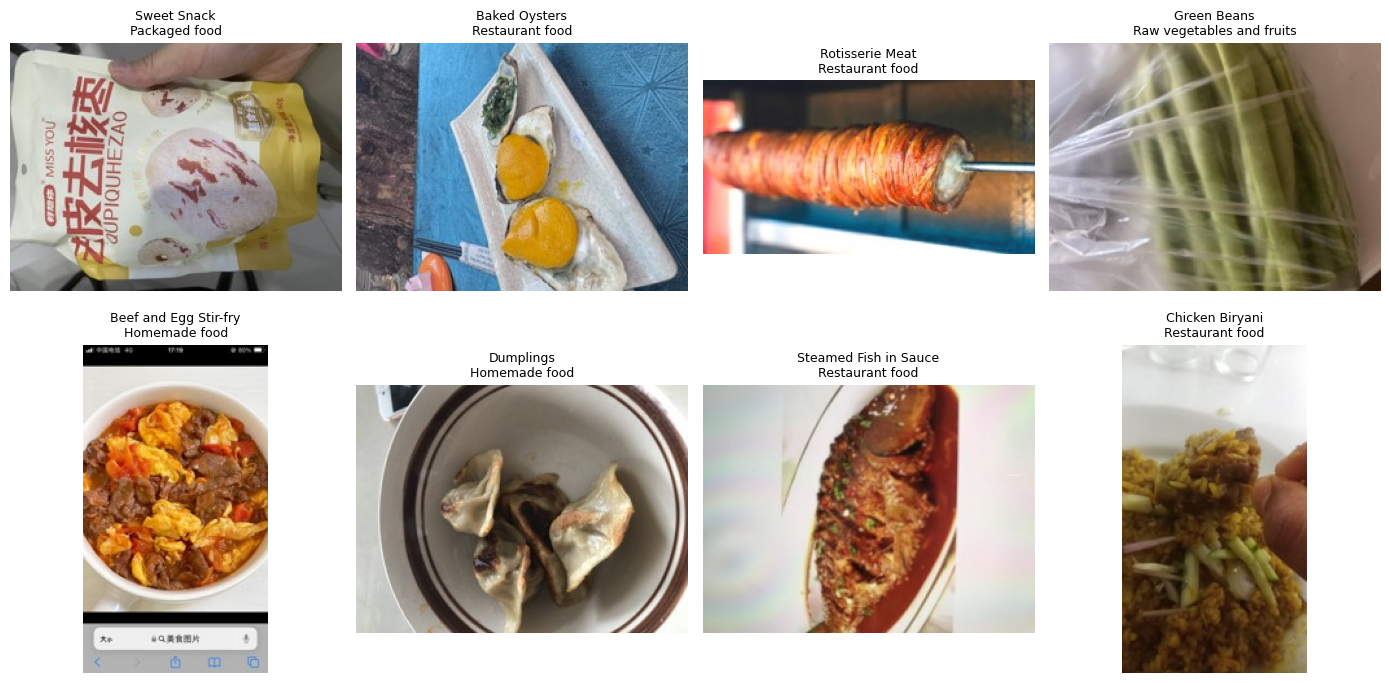

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Tampilkan 8 gambar acak beserta nama hidangan dan jenis makanannya
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, r) in zip(axes.ravel(), sub.sample(8, random_state=1).iterrows()):
    ax.imshow(Image.open(f"{P.local_images}/{r.fname}"))
    ax.set_title(f"{r.dish_name}\n{r.food_type}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{P.figures}/sample_images.png", dpi=110)
plt.show()